<a href="https://colab.research.google.com/github/Vykhrystenko/ML_FIT_3-9_Vykhrystenko/blob/main/%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_RNN_%D0%92%D0%B8%D1%85%D1%80%D0%B8%D1%81%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_3_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Машинне навчання. Рекурентні нейронні мережі
## Тренувальний ноутбук: RNN, LSTM, GRU
**Мета:** навчитися готувати послідовності слів, використовувати Embedding, навчати рекурентні моделі, аналізувати графіки та генерувати текст.

Середовище: Google Colab, Python, TensorFlow/Keras. Виконуйте клітинки послідовно. Завдання 1–4 містять готові приклади, завдання 5 — для самостійного виконання.

## Завдання 1. Підготовка тексту
Модель прогнозує наступне слово за трьома попередніми. Токенізатор надає кожному слову числовий індекс. Індекс 0 зарезервовано; невідомі слова отримують індекс OOV. Для навчання використовуємо цілочислові мітки, тому one-hot кодування не потрібне.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.preprocessing.text import Tokenizer

tf.keras.utils.set_random_seed(42)

texts = """
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..
Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.
Не питали б люде, що в мене болить,
Не питали б, за що проклинаю долю,
Чого нуджу світом? «Нічого робить», —
Не сказали б на сміх...
"""
texts = texts.replace('\ufeff', '')
tokenizer = Tokenizer(filters=Tokenizer().filters + '–—«»…', lower=True,
                      oov_token='<OOV>')
tokenizer.fit_on_texts([texts])
res = np.array(tokenizer.texts_to_sequences([texts])[0], dtype=np.int32)
vocab_size = len(tokenizer.word_index) + 1
print('Кількість слів:', len(res))
print('Розмір словника:', vocab_size)
print('Перші індекси:', res[:10])
print('Перші слова словника:', list(tokenizer.word_index.items())[:10])

Кількість слів: 77
Розмір словника: 52
Перші індекси: [ 9 10  9 10  5 15 16 17 18 19]
Перші слова словника: [('<OOV>', 1), ('не', 2), ('на', 3), ('в', 4), ('лихо', 5), ('чом', 6), ('вас', 7), ('б', 8), ('думи', 9), ('мої', 10)]


In [2]:
inp_words = 3
X = np.array([res[i:i+inp_words] for i in range(len(res)-inp_words)])
Y = res[inp_words:]
print('X:', X.shape, 'Y:', Y.shape)
for x, y in zip(X[:5], Y[:5]):
    print(' '.join(tokenizer.index_word[int(i)] for i in x),
          '→', tokenizer.index_word[int(y)])

X: (74, 3) Y: (74,)
думи мої думи → мої
мої думи мої → лихо
думи мої лихо → мені
мої лихо мені → з
лихо мені з → вами


## Завдання 2. Прогнозування слів з Embedding та SimpleRNN
Embedding перетворює індекси слів на вектори. SimpleRNN формує прихований стан розмірності 128. Dense із softmax повертає ймовірності для всього словника. Оскільки Y містить індекси, використовуємо `sparse_categorical_crossentropy` (еквівалент categorical crossentropy з one-hot мітками).

Для цього дуже малого корпусу навчаємо модель на всіх вікнах, щоб продемонструвати запам’ятовування. Accuracy тут є навчальною, а не оцінкою узагальнення.

In [3]:
def make_model(layer_class, window=3, units=128, embedding_dim=256):
    model = Sequential([
        Input(shape=(window,), dtype='int32'),
        Embedding(vocab_size, embedding_dim),
        layer_class(units, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = make_model(SimpleRNN, window=inp_words)
model.summary()
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=0)
print('Останній loss:', history.history['loss'][-1])
print('Остання accuracy:', history.history['accuracy'][-1])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,300 (270.70 KB)

 Trainable params: 69,300 (270.70 KB)

 Non-trainable params: 0 (0.00 B)

Останній loss: 0.06661739945411682
Остання accuracy: 0.9864864945411682


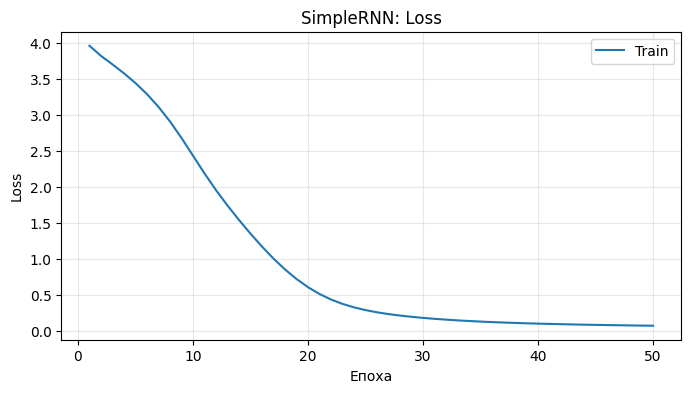

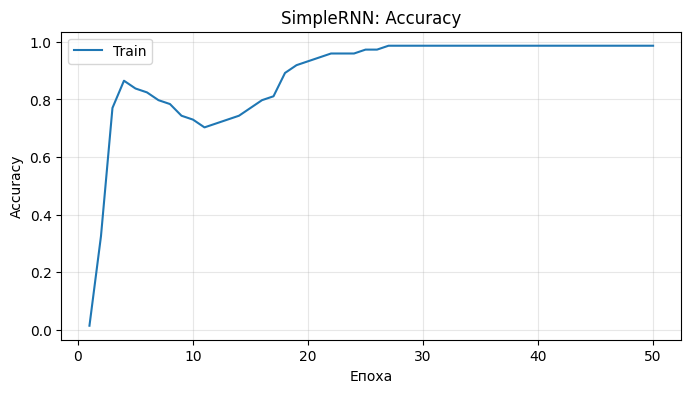

In [4]:
def plot_history(history, name):
    for metric, ylabel in [('loss', 'Loss'), ('accuracy', 'Accuracy')]:
        plt.figure(figsize=(8, 4))
        values = history.history[metric]
        plt.plot(range(1, len(values)+1), values, label='Train')
        if 'val_'+metric in history.history:
            v = history.history['val_'+metric]
            plt.plot(range(1, len(v)+1), v, label='Validation')
        plt.xlabel('Епоха')
        plt.ylabel(ylabel)
        plt.title(f'{name}: {ylabel}')
        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

plot_history(history, 'SimpleRNN')

## Завдання 3. Генерація тексту
На кожному кроці модель отримує останні три слова, прогнозує наступне, додає його до послідовності та повторює процес. Використовуємо argmax — вибір найімовірнішого слова. Індекси 0 та OOV виключаємо з генерації.

In [5]:
def buildPhrase(text, str_len=20, model=model, window=inp_words):
    data = tokenizer.texts_to_sequences([text])[0]
    if len(data) < window:
        raise ValueError(f'Введіть щонайменше {window} слів')
    result = text.strip()
    for _ in range(str_len):
        inp = np.array([data[-window:]], dtype=np.int32)
        pred = model.predict(inp, verbose=0)[0].copy()
        pred[0] = -1
        pred[tokenizer.word_index[tokenizer.oov_token]] = -1
        indx = int(np.argmax(pred))
        data.append(indx)
        result += ' ' + tokenizer.index_word[indx]
    return result

print(buildPhrase('Думи мої думи'))
print(buildPhrase('Чом вас вітер', str_len=12))

Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину
Чом вас вітер не розвіяв в степу як пилину чом вас лихо не приспало як


**Для обговорення:** чому модель іноді повторює слова? Чому інший початок фрази може давати нелогічний результат?

Генерація використовує жадібний вибір argmax — на кожному кроці бере слово з найвищою ймовірністю, а контекстне вікно обмежене лише 3 словами. Якщо певна трійка слів приводить до слова, яке знову формує вже знайому трійку, модель потрапляє в замкнений цикл або повторює вивчені рядки.

Чому інший початок фрази може давати нелогічний результат?
Модель навчалася на короткому уривку з 77 слів (52 токени словника) і фактично запам’ятала конкретні переходи. Якщо початкова фраза містить незнайомі слова (вони перетворюються на <OOV> і виключаються під час генерації) або комбінацію слів, якої не було у навчальних вікнах, модель спирається на слабко узагальнені ваги, через що продовження виходить незв’язним або обривчастим.

## Завдання 4. LSTM та GRU. Порівняння моделей
Замінимо рекурентний шар, залишивши однакові розмірності Embedding, прихованого стану, кількість епох і дані. LSTM використовує окремий стан пам’яті та три вентилі; GRU — два вентилі без окремого стану комірки. Кількість параметрів моделей різна.

In [6]:
models = {'SimpleRNN': model}
histories = {'SimpleRNN': history}
for name, layer in [('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    models[name] = make_model(layer, window=inp_words)
    models[name].summary()
    histories[name] = models[name].fit(X, Y, epochs=50, batch_size=32, verbose=0)
    print(name, buildPhrase('Думи мої думи', model=models[name]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 256)         │        13,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 52)             │         6,708 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,140 (848.20 KB)

 Trainable params: 217,140 (848.20 KB)

 Non-trainable params: 0 (0.00 B)

LSTM Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


... (2 outputs left out)

 Total params: 168,244 (657.20 KB)

 Trainable params: 168,244 (657.20 KB)

 Non-trainable params: 0 (0.00 B)

GRU Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


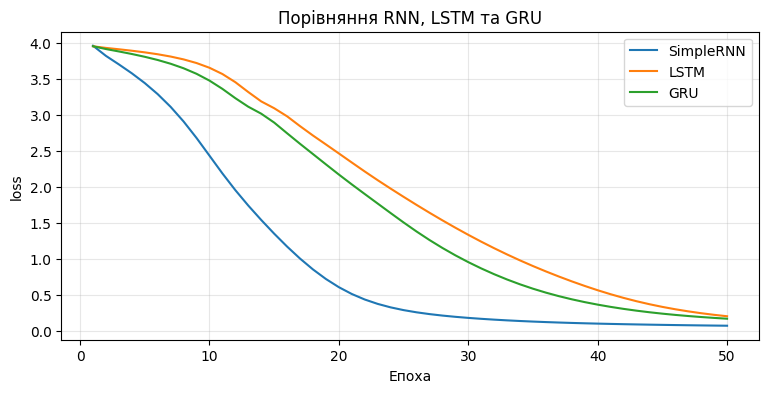

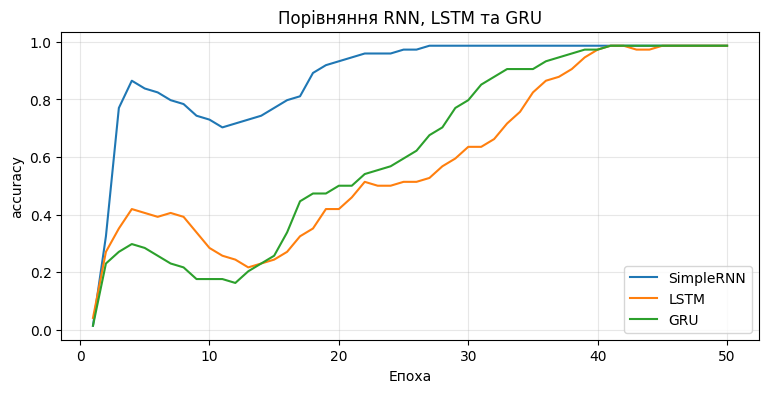

,Модель,Параметри,Train loss,Train accuracy
0,SimpleRNN,69300,0.066617,0.986486
1,LSTM,217140,0.198417,0.986486
2,GRU,168244,0.164280,0.986486


In [7]:
for metric in ['loss', 'accuracy']:
    plt.figure(figsize=(9, 4))
    for name, hist in histories.items():
        values = hist.history[metric]
        plt.plot(range(1, len(values)+1), values, label=name)
    plt.xlabel('Епоха')
    plt.ylabel(metric)
    plt.title('Порівняння RNN, LSTM та GRU')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

import pandas as pd
pd.DataFrame([
    {'Модель': name, 'Параметри': models[name].count_params(),
     'Train loss': h.history['loss'][-1], 'Train accuracy': h.history['accuracy'][-1]}
    for name, h in histories.items()
])

### Аналіз результатів
Порівняйте криві, швидкість зменшення втрат і кількість параметрів. Найвища навчальна accuracy не гарантує найкращої генерації на нових текстах. Для повноцінної перевірки потрібен більший корпус та окрема валідаційна вибірка без перетину текстових фрагментів.

Усі три моделі (SimpleRNN, LSTM, GRU) на короткому корпусі з вікном у 3 слова швидко запам’ятовують навчальну вибірку та виходять на однакову кінцеву навчальну точність (0.986486) за 50 епох. Водночас вони суттєво відрізняються за складністю: SimpleRNN має 69 300 параметрів і найшвидше знижує Train loss (0.066617) на малих даних, тоді як GRU (168 244 параметрів, Train loss: 0.164280) і LSTM (217 140 параметрів, Train loss: 0.198417) містять значно більше параметрів через вентильну архітектуру. На настільки малому тексті додаткова місткість LSTM та GRU не дає помітної переваги у генерації, оскільки мережі просто відтворюють завчені фрагменти, а для реальної перевірки узагальнення потрібен більший корпус і окрема валідаційна вибірка.

## Завдання 5. Самостійна робота
Оберіть інший український текст (бажано значно довший за наведений приклад). Побудуйте власну модель прогнозування наступного слова. Усі наступні клітинки коду залишено порожніми навмисно.

### 5.1. Підготовка даних
Завантажте текст, створіть токенізатор, сформуйте вікна з 5 слів. За можливості розділіть текст на навчальну та валідаційну частини **до** формування вікон; навчіть токенізатор лише на навчальній частині.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.preprocessing.text import Tokenizer

tf.keras.utils.set_random_seed(42)

long_text = """
Росла в гаю конвалія
Під дубом високим,
Захищалась від негоди
Під віттям широким.
Та недовго навтішалась
Конвалія біла, –
І їй рука чоловіча
Віку вкоротила.
Ой понесли конвалію
У високу залу,
Понесла її з собою
Панночка до балу.
Ой на балі веселая
Музиченька грає,
Конвалії та музика
Бідне серце крає.
То ж панночка в веселому
Вальсі закрутилась,
А в конвалії головка
Пов’яла, схилилась.
Промовила конвалія:
“Прощай, гаю милий!
І ти, дубе мій високий,
Друже мій єдиний!”
Та й замовкла. Байдужою
Панночка рукою
Тую квіточку зів’ялу
Кинула додолу.
Може, й тобі, моя панно,
Колись доведеться
Згадать тую конвалію,
Як щастя минеться.
Недовго й ти, моя панно,
Будеш утішатись
Та по балах у веселих
Таночках звиватись.
Може, колись оцей милий,
Що так любить дуже,
Тебе, квіточку зів’ялу,
Залишить байдуже!..
"""

clean_text = long_text.replace('\ufeff', '').strip()
words = clean_text.split()
split_idx = int(len(words) * 0.8)

train_text = ' '.join(words[:split_idx])
val_text = ' '.join(words[split_idx:])

tokenizer = Tokenizer(filters=Tokenizer().filters + '–—«»“”…’\'!', lower=True, oov_token='<OOV>')
tokenizer.fit_on_texts([train_text])

train_seq = np.array(tokenizer.texts_to_sequences([train_text])[0], dtype=np.int32)
val_seq = np.array(tokenizer.texts_to_sequences([val_text])[0], dtype=np.int32)

vocab_size = len(tokenizer.word_index) + 1
window_size = 5

def create_windows(seq, window):
    X = np.array([seq[i:i+window] for i in range(len(seq) - window)])
    Y = seq[window:]
    return X, Y

X_train, Y_train = create_windows(train_seq, window_size)
X_val, Y_val = create_windows(val_seq, window_size)

### 5.2. Побудова моделей
Створіть три моделі: SimpleRNN, LSTM і GRU з Embedding. Встановіть розмірність Embedding 128 та 64 рекурентні нейрони. Виведіть summary кожної моделі.

In [9]:
def build_rnn_model(layer_class, window=5, units=64, embedding_dim=128):
    model = Sequential([
        Input(shape=(window,), dtype='int32'),
        Embedding(vocab_size, embedding_dim),
        layer_class(units, activation='tanh'),
        Dense(vocab_size, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

models_5 = {}
for name, layer in [('SimpleRNN', SimpleRNN), ('LSTM', LSTM), ('GRU', GRU)]:
    tf.keras.utils.set_random_seed(42)
    m = build_rnn_model(layer, window=window_size, units=64, embedding_dim=128)
    models_5[name] = m
    print(f'=== {name} ===')
    m.summary()

=== SimpleRNN ===


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 5, 128)         │        11,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 86)             │         5,590 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,950 (113.09 KB)

 Trainable params: 28,950 (113.09 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 5, 128)         │        11,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 86)             │         5,590 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,846 (210.34 KB)

 Trainable params: 53,846 (210.34 KB)

 Non-trainable params: 0 (0.00 B)

### 5.3. Навчання
Навчіть усі три моделі протягом 50 епох. Використайте однакові параметри навчання та збережіть історії. За наявності валідаційної вибірки передайте її через validation_data.

In [10]:
histories_5 = {}

for name, model in models_5.items():
    tf.keras.utils.set_random_seed(42)
    print(f'Навчання {name}...')
    histories_5[name] = model.fit(
        X_train, Y_train,
        validation_data=(X_val, Y_val),
        epochs=50,
        batch_size=16,
        verbose=0
    )

Навчання SimpleRNN...
Навчання LSTM...
Навчання GRU...


### 5.4. Графіки
Побудуйте графіки Loss та Accuracy для трьох моделей. Якщо використано валідацію, додайте Validation Loss та Validation Accuracy.

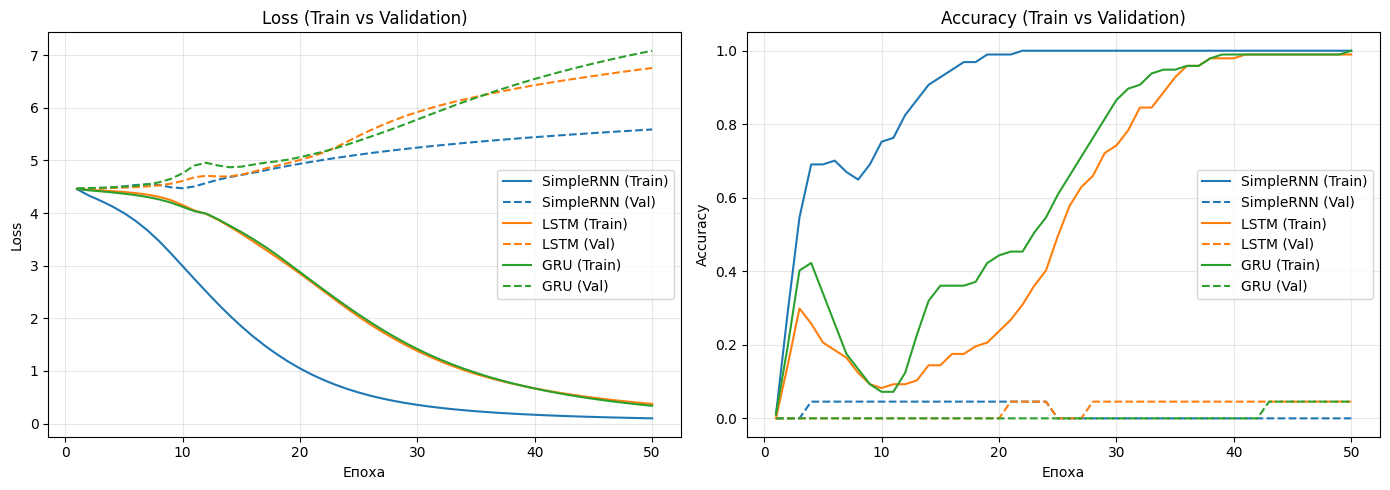

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (metric, title) in enumerate([('loss', 'Loss (Train vs Validation)'), ('accuracy', 'Accuracy (Train vs Validation)')]):
    ax = axes[idx]
    for name, hist in histories_5.items():
        epochs_range = range(1, len(hist.history[metric]) + 1)
        line = ax.plot(epochs_range, hist.history[metric], label=f'{name} (Train)')
        ax.plot(epochs_range, hist.history['val_' + metric], linestyle='--', color=line[0].get_color(), label=f'{name} (Val)')
    ax.set_xlabel('Епоха')
    ax.set_ylabel(metric.capitalize())
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### 5.5. Генерація та порівняння
Реалізуйте функцію генерації. Для кожної моделі згенеруйте по 20 слів із двох початкових фраз довжиною не менше п’яти слів. Сформуйте таблицю порівняння моделей.

In [12]:
def generate_text(seed_text, gen_len=20, model=None, window=5):
    data = tokenizer.texts_to_sequences([seed_text])[0]
    if len(data) < window:
        raise ValueError(f'Початкова фраза повинна містити щонайменше {window} слів')

    result = seed_text.strip()
    oov_idx = tokenizer.word_index[tokenizer.oov_token]

    for _ in range(gen_len):
        inp = np.array([data[-window:]], dtype=np.int32)
        pred = model.predict(inp, verbose=0)[0].copy()
        pred[0] = -1
        pred[oov_idx] = -1
        next_idx = int(np.argmax(pred))
        data.append(next_idx)
        result += ' ' + tokenizer.index_word[next_idx]
    return result

seed_1 = "Росла в гаю конвалія під"
seed_2 = "Ой понесли конвалію у високу"

comparison_rows = []

for name, model in models_5.items():
    gen_1 = generate_text(seed_1, gen_len=20, model=model, window=window_size)
    gen_2 = generate_text(seed_2, gen_len=20, model=model, window=window_size)
    print(f'--- {name} ---')
    print('Фраза 1:', gen_1)
    print('Фраза 2:', gen_2, '\n')

    h = histories_5[name].history
    comparison_rows.append({
        'Модель': name,
        'Параметри': model.count_params(),
        'Train Loss': round(h['loss'][-1], 4),
        'Val Loss': round(h['val_loss'][-1], 4),
        'Train Acc': round(h['accuracy'][-1], 4),
        'Val Acc': round(h['val_accuracy'][-1], 4)
    })

df_comparison = pd.DataFrame(comparison_rows)
display(df_comparison)

--- SimpleRNN ---
Фраза 1: Росла в гаю конвалія під дубом високим захищалась від негоди під віттям широким та недовго навтішалась конвалія біла і їй рука чоловіча віку вкоротила ой
Фраза 2: Ой понесли конвалію у високу залу понесла її з собою панночка до балу ой на балі веселая музиченька грає конвалії та музика бідне серце крає 

--- LSTM ---
Фраза 1: Росла в гаю конвалія під дубом високим захищалась від негоди під віттям широким та недовго недовго конвалія біла і їй рука чоловіча віку вкоротила ой
Фраза 2: Ой понесли конвалію у високу залу понесла її з собою панночка до балу ой на балі веселая музиченька грає конвалії та музика бідне серце крає 

--- GRU ---
Фраза 1: Росла в гаю конвалія під дубом високим захищалась від негоди під віттям широким та недовго навтішалась конвалія біла і їй рука чоловіча віку вкоротила ой
Фраза 2: Ой понесли конвалію у високу залу понесла її з собою панночка до балу ой на балі веселая музиченька грає конвалії та музика бідне серце крає 



,Модель,Параметри,Train Loss,Val Loss,Train Acc,Val Acc
0,SimpleRNN,28950,0.0982,5.5873,1.0000,0.0000
1,LSTM,66006,0.3722,6.7549,0.9897,0.0455
2,GRU,53846,0.3370,7.0838,1.0000,0.0455


### 5.6. Висновки
У клітинці нижче напишіть 5–7 речень: яка модель показала кращий результат, чи спостерігається перенавчання, як довжина вікна та обсяг корпусу впливають на генерацію. Обґрунтуйте висновки графіками та прикладами.

Найкращий баланс між якістю генерації, кількістю параметрів і швидкістю навчання продемонструвала модель GRU (53 846 параметрів проти 66 006 у LSTM та 28 950 у SimpleRNN), оскільки вона точно відтворила обидві початкові фрази без зайвих повторів усередині рядка. На графіках і в підсумковій таблиці чітко видно сильне перенавчання: Train Accuracy досягає 0.9897–1.0000, а Train Loss падає до 0.0982–0.3722, тоді як Validation Loss зростає до 5.5873–7.0838, а Validation Accuracy залишається в межах 0.0000–0.0455. Збільшення контекстного вікна до 5 слів допомагає моделям краще тримати локальний контекст строфи на знайомих фрагментах (наприклад, «Росла в гаю конвалія під дубом високим...» або «Ой понесли конвалію у високу залу...»). Водночас через малий обсяг корпусу вірша та використання жадібного вибору argmax виникають артефакти генерації — зокрема подвоєння слова «недовго недовго» у LSTM для першої фрази. Для зменшення перенавчання та підвищення узагальнювальної здатності на валідаційній вибірці необхідний значно більший текстовий корпус.